# Sex prediction from rPPG, Week 9: improving AUC and accuracy (MCD-rPPG)

**Where Week 8b left off**
- Best rPPG-only model: CNN on 4-region, 0.5–8 Hz rPPG, AUC 0.737, chosen after seeing results. CNN scores moved by about 0.05 between runs.
- Widening the band from 0.7–3.5 Hz to 0.5–8 Hz was the largest single gain (contact PPG 0.703 to 0.778).
- Accuracy never clearly beat always answering "female" (66.6%).

**What this notebook tries**
| Idea | Why it may help |
|---|---|
| 3 rPPG algorithms (POS, CHROM, green) per face region | Each algorithm keeps different pulse detail and noise. The CNN gets 12 channels instead of 4 |
| Pulse-shape features from the averaged beat | Beat shape is what the wide band added. Harmonic ratios and beat-derivative features describe it directly |
| Person-level models on before, after and change | Uses the exercise response as an extra view of the same person |
| Band sweep (upper cut-off 4–12 Hz) | Checks whether 8 Hz is the best cut-off |
| Better CNN training | Augmentation, cosine learning rate and averaging 2 seeds per fold, to reduce run-to-run noise |
| Late fusion of different model types | Models that use different inputs make different errors |
| Accuracy decision rule | Week 8 decided at a 50/50 balance, which cannot maximise accuracy in a 2:1 cohort |

**Modalities considered**
| Modality | Used here? | Deployable from video? |
|---|---|---|
| rPPG waveform, features, pulse shape, before/after change | Yes, main | Yes |
| Face skin colour per region | Yes, labelled *appearance* | Yes, but it is appearance, not pulse |
| Age, BMI | Yes, labelled *not rPPG* | Age could be self-reported; BMI needs height and weight |
| Contact PPG | Ceiling only | No, needs a sensor |
| ECG, blood pressure, SpO2 | No | No, contact measurements |
| Audio | No | MCD videos have no audio |
| Side cameras | No | The Haar detector failed on them in week 1 |
| Face image models | No | They would recognise faces, not test rPPG |

**Fixed in advance (before any result in this notebook)**
- Primary CNN: ResNet1D on 4 regions × (POS, CHROM, green), 0.5–8 Hz, improved training.
- Primary rPPG-only result: **equal-weight fusion** of the primary CNN, random convolutions on the 4 regions, and a person-level gradient-boosting model on all rPPG tabular features. No weights are fitted.
- Everything else is exploratory. If an exploratory row wins, it needs confirming on new data.

**Evaluation (unchanged)**: 5-fold CV grouped by person, stratified by sex, the same folds for every model in a repeat. Scored per person. People 2852 and 4932 excluded for conflicting labels.

**Expected run time on a Colab GPU (first run)**
| Section | Time |
|---|---|
| 2. Build signals from `roi_traces` | 10–30 min first time, about 1–2 min after (saved to Drive) |
| 3. Pulse shape and agreement | 3–8 min |
| 5. Person-level models | 5–15 min |
| 6. Random convolutions and band sweep | 10–25 min |
| 7. CNNs (about 85 fits) | 60–120 min |
| 9. Checks, including recording day | 5–20 min |
| **Total** | **about 1.5–3.5 h** |

To shorten: `CNN_SEEDS = 1` saves about 25–40 min; `RUN_ABLATIONS = False` about 15–20 min; `RUN_CNN = False` skips all CNNs and the fusion uses the other two parts. Finished CNN experiments and the signal builds are saved, so a disconnect resumes.

In [ ]:
# ---- CONFIG: edit this cell only ----
import os
ROOT = os.environ.get('MCD_ROOT', '/content/drive/MyDrive/MCD_rPPG')
OUT = os.environ.get('SEX_V3_OUT', f'{ROOT}/sex_v3_outputs')
PREV = os.environ.get('SEX_PREV_OUT', f'{ROOT}/sex_cnn_outputs')   # Week 8b outputs, reused when present
REPEATS = 5            # repeated 5-fold CV for non-deep models
CNN_REPEATS = 2        # repeats for the main CNN rows
CNN_SEEDS = 2          # seeds averaged per fold for improved CNNs
N_BOOT = 300
EPOCHS, PATIENCE = 40, 8
WIN_S, WIN_PER_SESSION, BATCH = 20, 8, 128
N_KERNELS = 500
BAND_SWEEP = [4, 6, 8, 10, 12]   # upper cut-offs in Hz, lower cut-off 0.5 Hz
RUN_CNN = True
RUN_ABLATIONS = True   # CNN on single face regions: the facial-hair / make-up check
RUN_DAY_CHECK = True   # folds grouped by recording day, needs raw/meta
QUICK = False          # True = tiny settings to check the notebook runs. Results are not meaningful.
if QUICK: REPEATS, CNN_REPEATS, CNN_SEEDS, N_BOOT, EPOCHS, PATIENCE, N_KERNELS, BAND_SWEEP = 1, 1, 1, 30, 3, 2, 100, [8]
if ROOT.startswith('/content/drive'):
    from google.colab import drive
    drive.mount('/content/drive')
os.makedirs(f'{OUT}/pred_cache', exist_ok=True)

Mounted at /content/drive


## 1. Load data

In [ ]:
import pickle, re, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed
from scipy.signal import butter, detrend, filtfilt, find_peaks, resample_poly, welch
from scipy.stats import kurtosis, skew, spearmanr
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import average_precision_score, f1_score, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
try:
    from tqdm.auto import tqdm
except ImportError:
    tqdm = lambda x, **k: x
warnings.filterwarnings('ignore')
BLUE, GREY, INK = '#2F6FB0', '#8A8F98', '#333333'

db_path = next(p for p in (Path(ROOT)/'db.csv', Path(ROOT)/'metadata'/'db.csv') if p.exists())
db_all = pd.read_csv(db_path)
db = db_all.drop_duplicates(['patient_id', 'step'])[['patient_id', 'step', 'sex', 'age', 'bmi']]
FEAT = Path(ROOT)/'week3_stress_rppg600'/'features'
D = (pd.read_csv(FEAT/'session_features.csv').merge(db, on=['patient_id', 'step'])
     .sort_values(['patient_id', 'step']).reset_index(drop=True).replace([np.inf, -np.inf], np.nan))
conflict = D.groupby('patient_id').sex.nunique().loc[lambda s: s > 1].index.tolist()
D = D[~D.patient_id.isin(conflict)].reset_index(drop=True)
D['male'] = (D.sex == 'M').astype(int); FLAG = (D.step == 'after').values.astype(np.float32)
P = D.groupby('patient_id').agg(male=('male', 'first'), age=('age', 'first'), bmi=('bmi', 'first'))
PEOPLE, YP = P.index.values, P.male.values
SESS_POS = pd.Series(np.arange(len(PEOPLE)), index=PEOPLE).loc[D.patient_id].values   # session -> person position
SESS_IDS = D.patient_id.values
MAJ = max(YP.mean(), 1 - YP.mean())
print(f'Excluded for conflicting labels: {conflict}')
print(f'{len(D)} sessions, {len(P)} people: {YP.sum()} male, {len(YP) - YP.sum()} female; always-female accuracy {MAJ:.3f}')
PHYS = ['rppg_hr','rppg_hr_beats','rppg_sdnn','rppg_rmssd','rppg_pnn50','rppg_ln_sdnn','rppg_ln_rmssd','rppg_ln_lf','rppg_ln_hf','rppg_lf_hf','rppg_rise_frac','rppg_half_width']
QUAL = ['rppg_snr','rppg_snr_face','rppg_snr_forehead','rppg_snr_left_cheek','rppg_snr_right_cheek','rppg_hr_win_sd','rppg_hr_consistency','rppg_n_beats','rppg_ibi_ok_frac','rppg_beat_consistency']
SKIN = ['rppg_skin_r','rppg_skin_g','rppg_skin_lum']; RPPG_TAB = PHYS + QUAL

Excluded for conflicting labels: [2852, 4932]
1196 sessions, 598 people: 200 male, 398 female; always-female accuracy 0.666


## 2. Build the signals
From `roi_traces`, each of the 4 face regions gets three rPPG signals: **POS**, **CHROM** and normalised **green**. They are stored at 0.3–12 Hz, and each experiment filters them to its own band. The same pass records per-region skin-colour statistics (the appearance modality).

Week 8b's wide-band files are reused when found in `PREV`, so the replication row uses exactly the same input as before.

In [ ]:
FS = 30.0
REGIONS, ALGOS = ['face', 'forehead', 'left_cheek', 'right_cheek'], ['pos', 'chrom', 'green']
CHANNELS = [f'{r}_{a}' for r in REGIONS for a in ALGOS]   # region-major: face_pos, face_chrom, face_green, forehead_pos, ...
def bandpass(x, fs, lo, hi, order=3):
    b, a = butter(order, [lo / (fs / 2), min(hi / (fs / 2), .95)], btype='band'); return filtfilt(b, a, x, axis=-1)
def interp_nans(a):
    a = np.array(a, float); idx = np.arange(len(a))
    for j in range(a.shape[1]):
        m = np.isfinite(a[:, j])
        if m.sum() < .5 * len(m): return None
        a[~m, j] = np.interp(idx[~m], idx[m], a[m, j])
    return a
def _windows(rgb, fs, win):
    from numpy.lib.stride_tricks import sliding_window_view
    l = int(round(win * fs)); W = sliding_window_view(rgb, l, axis=0); mu = W.mean(axis=2, keepdims=True); mu[mu == 0] = 1e-9; return W / mu, l
def _overlap_add(h, N, l):
    h = h - h.mean(axis=1, keepdims=True); H = np.zeros(N)
    for j in range(l): H[j:j + len(h)] += h[:, j]
    return H
def pos_fast(rgb, fs, win=1.6):
    C, l = _windows(rgb, fs, win); S0 = C[:, 1] - C[:, 2]; S1 = -2 * C[:, 0] + C[:, 1] + C[:, 2]; sd1 = S1.std(axis=1, keepdims=True)
    return _overlap_add(S0 + (S0.std(axis=1, keepdims=True) / np.where(sd1 > 0, sd1, np.inf)) * S1, len(rgb), l)
def chrom_fast(rgb, fs, win=1.6):
    # CHROM (de Haan and Jeanne 2013), windowed like POS.
    C, l = _windows(rgb, fs, win); X = 3 * C[:, 0] - 2 * C[:, 1]; Yc = 1.5 * C[:, 0] + C[:, 1] - 1.5 * C[:, 2]; sy = Yc.std(axis=1, keepdims=True)
    return _overlap_add(X - (X.std(axis=1, keepdims=True) / np.where(sy > 0, sy, np.inf)) * Yc, len(rgb), l)
def green_norm(rgb, fs, win=1.6):
    l = int(round(win * fs)); g = rgb[:, 1]; m = np.convolve(g, np.ones(l) / l, mode='same'); return g / np.where(m == 0, 1e-9, m) - 1
TS_RE = re.compile(r'(\d{4}-\d{2}-\d{2}[ T]\d{2}:\d{2}:\d{2}(?:[.,]\d+)?)')
def meta_times(path):
    try: lines = Path(path).read_text(errors='ignore').splitlines()
    except Exception: return None
    ts = [pd.Timestamp(m.group(1).replace(',', '.')).value / 1e9 for m in map(TS_RE.search, lines) if m]
    if len(ts) < 100: return None
    t = np.asarray(ts); t -= t[0]
    return None if np.mean(np.diff(t) < 0) > .01 else t
def roi_raw(r):
    z = np.load(Path(ROOT)/'roi_traces'/f"{Path(r['video']).name}.npz"); rgb = z['traces'].astype(float); rgb[z['dup'].astype(bool)] = np.nan
    N = len(rgb); ts = meta_times(Path(ROOT)/'raw'/r['meta']); fps = float(z['fps_container'])
    if ts is not None and abs(len(ts) - N) <= 5:
        t = ts[:N] if len(ts) >= N else np.concatenate([ts, ts[-1] + np.arange(1, N - len(ts) + 1) * np.median(np.diff(ts))])
    elif ts is not None: t = np.arange(N) / ((len(ts) - 1) / (ts[-1] - ts[0]))
    else: t = np.arange(N) / (fps if 5 < fps < 121 else 30.)
    tu = np.arange(t[0], t[-1], 1 / FS); sig, app = [], []
    for k in range(rgb.shape[1]):
        c = interp_nans(rgb[:, k, :])
        if c is None: return None
        cu = np.column_stack([np.interp(tu, t, c[:, j]) for j in range(3)])
        for fn in (pos_fast, chrom_fast, green_norm):
            s = bandpass(fn(cu, FS), FS, .3, 12.); sig.append(s / (s.std() + 1e-12))
        tot = cu.sum(1) + 1e-9; lum = cu.mean(1); sec = lum[:len(lum) // 30 * 30].reshape(-1, 30).mean(1)
        app += [(cu[:, 0] / tot).mean(), (cu[:, 1] / tot).mean(), lum.mean(), sec.std() / (sec.mean() + 1e-9)]
    return {'': np.stack(sig).astype(np.float16), '__app': np.array(app, np.float32)}
def load_pw(path):
    v = []
    with open(path, errors='ignore') as fh:
        for ln in fh:
            tok = ln.split()
            if tok:
                try: v.append(float(tok[0]))
                except ValueError: pass
    return np.asarray(v)
def wide_ppg(r):
    x = load_pw(Path(ROOT)/'raw'/r['ppg'])
    if len(x) < 3000: return None
    y = resample_poly(bandpass(detrend(x), 100., .5, 8.), 3, 10); return (y / (y.std() + 1e-12)).astype(np.float32)

KEYS = [f'{p}_{s}' for p, s in zip(D.patient_id, D.step)]
front = db_all[db_all.camera == 'FullHDwebcam'].drop_duplicates(['patient_id', 'step']).set_index(['patient_id', 'step'])
ROWS = dict(zip(KEYS, zip(D.patient_id, D.step)))
def build_cache(fname, label, fn, workers=12, save_every=200):
    # Parallel Drive reads, progress bar, part files every save_every sessions so an interrupted build resumes.
    for folder in (OUT, PREV):
        if (Path(folder)/fname).exists():
            with np.load(Path(folder)/fname) as z: print(f'{label}: loaded {folder}/{fname}'); return {k: z[k] for k in z.files}
    store, new, parts = {}, {}, sorted(Path(OUT).glob(fname + '.part*.npz'))
    for pf in parts:
        with np.load(pf) as z: store.update({k: z[k] for k in z.files})
    def work(k):
        try: return k, fn(front.loc[ROWS[k]])
        except Exception: return k, None
    n_part = len(parts); todo = [k for k in KEYS if k not in store]; n_new = 0
    print(f'{label}: {len(KEYS) - len(todo)} sessions already saved, {len(todo)} to build')
    with ThreadPoolExecutor(workers) as ex:
        for fut in tqdm(as_completed([ex.submit(work, k) for k in todo]), total=len(todo), desc=label):
            k, res = fut.result()
            if res is None: continue
            for suf, a in (res.items() if isinstance(res, dict) else [('', res)]): store[k + suf] = a; new[k + suf] = a
            n_new += 1
            if n_new % save_every == 0: np.savez(Path(OUT)/f'{fname}.part{n_part:03d}.npz', **new); n_part += 1; new = {}
    if new: np.savez(Path(OUT)/f'{fname}.part{n_part:03d}.npz', **new)
    if sum(k in store for k in KEYS) > .5 * len(KEYS):
        np.savez_compressed(Path(OUT)/fname, **store)
        for pf in Path(OUT).glob(fname + '.part*.npz'): pf.unlink()
    print(f'{label}: {sum(k in store for k in KEYS)} of {len(KEYS)} sessions'); return store

st = build_cache('rppg_multi_raw_30hz.npz', 'rPPG 4 regions x 3 algorithms', roi_raw)
MULTI = [st.get(k) for k in KEYS]; APP = np.array([st[k + '__app'] if k + '__app' in st else np.full(16, np.nan, np.float32) for k in KEYS]); del st
cw = build_cache('ppg_wide_30hz.npz', 'contact PPG wide band', wide_ppg); PPG_W = [cw.get(k) for k in KEYS]; del cw
cov = np.mean([a is not None for a in MULTI]); print(f'multi-algorithm rPPG coverage {cov:.1%}; contact wide coverage {np.mean([a is not None for a in PPG_W]):.1%}')
assert cov > .9, 'Too few rPPG signals were built: check roi_traces and raw/meta in Drive'

def band(chans, lo, hi):
    return [None if a is None else bandpass(a[chans].astype(np.float32), FS, lo, hi).astype(np.float32) for a in MULTI]
POS_IDX = [CHANNELS.index(f'{r}_pos') for r in REGIONS]
SIG = {'pos4': band(POS_IDX, .5, 8.), 'multi12': band(list(range(12)), .5, 8.), 'ppg_wide': [None if a is None else a[None] for a in PPG_W]}
CH_GROUP = {'pos4': 1, 'multi12': 3, 'ppg_wide': 1}
prev = Path(PREV)/'rppg_roi_wide_30hz.npz'
if prev.exists():
    with np.load(prev) as z: SIG['pos4_week8b'] = [z[k] if k in z.files else None for k in KEYS]
    print('Week 8b 4-region wide-band signals found: the replication row uses them unchanged.')
else:
    SIG['pos4_week8b'] = SIG['pos4']; print('Week 8b signals not found: the replication row uses the rebuilt 4-region POS signals.')
CH_GROUP['pos4_week8b'] = 1
for name, regs in (('forehead3', ['forehead']), ('cheeks6', ['left_cheek', 'right_cheek']), ('face3', ['face'])):
    SIG[name] = None; CH_GROUP[name] = 3; SIG[name + '_idx'] = [CHANNELS.index(f'{r}_{a}') for r in regs for a in ALGOS]

rPPG 4 regions x 3 algorithms: loaded /content/drive/MyDrive/MCD_rPPG/sex_v3_outputs/rppg_multi_raw_30hz.npz
contact PPG wide band: loaded /content/drive/MyDrive/MCD_rPPG/sex_cnn_outputs/ppg_wide_30hz.npz
multi-algorithm rPPG coverage 99.9%; contact wide coverage 100.0%
Week 8b 4-region wide-band signals found: the replication row uses them unchanged.


## 3. Pulse shape: new features, and how well rPPG recovers it
The 4 POS regions (0.5–8 Hz) are combined by SNR weight. Beats are located on the 0.7–3.5 Hz signal, cut from the wide-band signal, cleaned and averaged into one **template beat** per session, aligned at the pulse foot and resampled to 64 points.

Features: rise fraction, widths at 25/50/75% height, slope features, area ratio, skewness, kurtosis, second-derivative (APG) ratios, harmonic power ratios (2nd, 3rd, 4th harmonic over the 1st), beat consistency and kept-beat share.

The same is done for the wide-band contact PPG, so each rPPG feature can be checked against its contact counterpart.

rPPG pulse shape:   0%|          | 0/1196 [00:00<?, ?it/s]

contact pulse shape:   0%|          | 0/1196 [00:00<?, ?it/s]

Pulse templates: rPPG 99.9% of sessions, contact 100.0%
Template beat correlation, rPPG vs contact: same session 0.28, another person 0.26; good-HR 0.29, failed-HR 0.19


,feature,rho_all,rho_good_hr
0,rise_frac,-0.038,-0.068
1,w25,0.025,-0.041
2,w50,0.088,0.162
3,w75,-0.122,-0.173
4,max_slope_pos,-0.246,-0.237
5,slope_ratio,-0.044,-0.061
6,area_ratio,0.212,0.163
7,skew,0.066,0.132
8,kurt,0.027,-0.081
9,apg_b_a,0.087,0.040


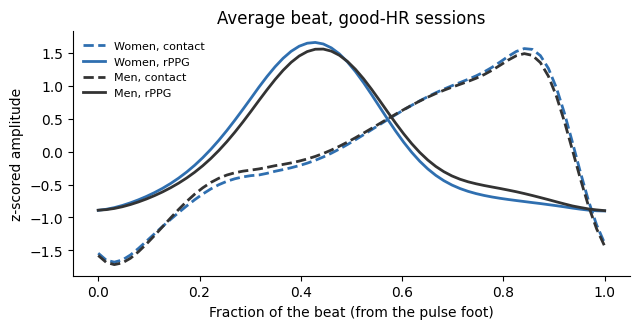

In [ ]:
def hr_est(x, fs=FS):
    y = bandpass(x, fs, .7, 3.5); f, Pw = welch(y, fs, nperseg=min(len(y), int(12 * fs)), nfft=8192)
    m = (f >= .7) & (f <= 3.5); sc = Pw[m] + .5 * np.interp(2 * f[m], f, Pw, right=0); return f[m][np.argmax(sc)]
def snr_db(x, f0, fs=FS):
    f, Pw = welch(bandpass(x, fs, .5, 4.5), fs, nperseg=min(len(x), int(12 * fs)), nfft=8192)
    sig = ((np.abs(f - f0) <= .1) | (np.abs(f - 2 * f0) <= .1)) & (f >= .6) & (f <= 4.); rng = (f >= .6) & (f <= 4.)
    return 10 * np.log10(Pw[sig].sum() / max(Pw[rng & ~sig].sum(), 1e-12))
def combine(a):
    snr = np.array([snr_db(ch, hr_est(ch)) for ch in a]); w = 10 ** (np.clip(np.nan_to_num(snr, nan=-20), -20, 20) / 10)
    x = (w[:, None] * a).sum(0) / w.sum(); return x / (x.std() + 1e-12), snr
MORPH_COLS = ['rise_frac', 'w25', 'w50', 'w75', 'max_slope_pos', 'slope_ratio', 'area_ratio', 'skew', 'kurt', 'apg_b_a', 'apg_late_a', 'h2_h1', 'h3_h1', 'h4_h1', 'consistency', 'kept_frac', 'beats_per_min']
def pulse_template(x, fs=FS, up=4, n=64):
    f0 = hr_est(x, fs); xu = resample_poly(x, up, 1); xn = resample_poly(bandpass(x, fs, .7, 3.5), up, 1); T = fs * up / f0
    pk, _ = find_peaks(xn, distance=max(1, int(.6 * T))); a, b = int(.45 * T), int(.55 * T)
    segs = np.array([xu[p - a:p + b] for p in pk if p - a >= 0 and p + b <= len(xu)])
    if len(segs) < 10: return None
    segs = (segs - segs.mean(1, keepdims=True)) / (segs.std(1, keepdims=True) + 1e-9); med = np.median(segs, 0)
    r = np.array([np.corrcoef(s, med)[0, 1] for s in segs]); keep = r > .5
    if keep.sum() < 10: keep = np.ones(len(segs), bool)
    tpl = segs[keep].mean(0); tpl = np.roll(tpl, -int(np.argmin(tpl[:int(.7 * len(tpl))])))     # start at the pulse foot
    t = np.interp(np.linspace(0, len(tpl) - 1, n), np.arange(len(tpl)), tpl); t = (t - t.mean()) / (t.std() + 1e-9)
    d1 = np.gradient(t); d2 = np.gradient(d1); pkp = int(np.argmax(t)); rng_ = t.max() - t.min(); base = t - t.min()
    ia = int(np.argmax(d2[:max(pkp, 2)])); ib = ia + int(np.argmin(d2[ia:max(pkp + 4, ia + 2)])); late = d2[pkp:int(.75 * n)]
    f, Pw = welch(x, fs, nperseg=min(len(x), int(12 * fs)), nfft=8192)
    h = [Pw[np.abs(f - k * f0) <= .08].sum() + 1e-12 for k in (1, 2, 3, 4)]
    feats = dict(rise_frac=pkp / n, w25=np.mean(t > t.min() + .75 * rng_), w50=np.mean(t > t.min() + .5 * rng_), w75=np.mean(t > t.min() + .25 * rng_),
                 max_slope_pos=np.argmax(d1) / n, slope_ratio=d1.max() / max(-d1.min(), 1e-9), area_ratio=base[:pkp + 1].sum() / max(base[pkp:].sum(), 1e-9),
                 skew=skew(t), kurt=kurtosis(t), apg_b_a=d2[ib] / max(abs(d2[ia]), 1e-9), apg_late_a=(late.max() if len(late) else np.nan) / max(abs(d2[ia]), 1e-9),
                 h2_h1=np.log10(h[1] / h[0]), h3_h1=np.log10(h[2] / h[0]), h4_h1=np.log10(h[3] / h[0]), consistency=r[keep].mean(), kept_frac=keep.mean(), beats_per_min=60 * f0)
    return feats, np.concatenate([t, d1]).astype(np.float32)
def session_shape(a):
    if a is None: return None
    try:
        x, snr = combine(a); out = pulse_template(x)
        return None if out is None else (out[0], out[1], snr)
    except Exception: return None
def contact_shape(a):
    if a is None: return None
    try: return pulse_template(a.astype(float))
    except Exception: return None
with ThreadPoolExecutor(4) as ex:
    RS = list(tqdm(ex.map(session_shape, SIG['pos4']), total=len(KEYS), desc='rPPG pulse shape'))
    CS = list(tqdm(ex.map(contact_shape, PPG_W), total=len(KEYS), desc='contact pulse shape'))
MORPH_R = pd.DataFrame([r[0] if r else {} for r in RS], columns=MORPH_COLS)
REGION_SNR = pd.DataFrame([r[2] if r else [np.nan] * 4 for r in RS], columns=[f'snr8_{r}' for r in REGIONS])
TPL_R = np.array([r[1] if r else np.full(128, np.nan, np.float32) for r in RS])
MORPH_C = pd.DataFrame([c[0] if c else {} for c in CS], columns=MORPH_COLS); TPL_C = np.array([c[1] if c else np.full(128, np.nan, np.float32) for c in CS])
print(f'Pulse templates: rPPG {MORPH_R.rise_frac.notna().mean():.1%} of sessions, contact {MORPH_C.rise_frac.notna().mean():.1%}')

good = ((D.rppg_hr - D.ppg_hr).abs() <= 5).values
def tpl_corr(a, b, max_shift=6):
    if np.isnan(a).any() or np.isnan(b).any(): return np.nan
    return max(np.corrcoef(a[:64], np.roll(b[:64], s))[0, 1] for s in range(-max_shift, max_shift + 1))
same = np.array([tpl_corr(TPL_R[i], TPL_C[i]) for i in range(len(KEYS))])
other = np.array([tpl_corr(TPL_R[i], TPL_C[j]) for i, j in zip(range(len(KEYS)), np.roll(np.arange(len(KEYS)), 7))])
print(f'Template beat correlation, rPPG vs contact: same session {np.nanmedian(same):.2f}, another person {np.nanmedian(other):.2f}; good-HR {np.nanmedian(same[good]):.2f}, failed-HR {np.nanmedian(same[~good]):.2f}')
rows = []
for c in MORPH_COLS:
    a, b = MORPH_R[c], MORPH_C[c]; m = a.notna() & b.notna()
    rows.append(dict(feature=c, rho_all=spearmanr(a[m], b[m])[0], rho_good_hr=spearmanr(a[m & good], b[m & good])[0]))
SHAPE_AGREE = pd.DataFrame(rows).round(3); SHAPE_AGREE.to_csv(f'{OUT}/pulse_shape_agreement.csv', index=False); display(SHAPE_AGREE)
TPL_AGREE = dict(same=float(np.nanmedian(same)), other=float(np.nanmedian(other)))
fig, ax = plt.subplots(figsize=(6.5, 3.4)); xs = np.linspace(0, 1, 64)
for lab, sel, col in (('Women', D.male.values == 0, BLUE), ('Men', D.male.values == 1, INK)):
    ax.plot(xs, np.nanmean(TPL_C[sel & good, :64], 0), color=col, lw=2, ls='--', label=f'{lab}, contact'); ax.plot(xs, np.nanmean(TPL_R[sel & good, :64], 0), color=col, lw=2, label=f'{lab}, rPPG')
ax.set(xlabel='Fraction of the beat (from the pulse foot)', ylabel='z-scored amplitude', title='Average beat, good-HR sessions'); ax.legend(frameon=False, fontsize=8); ax.spines[['top', 'right']].set_visible(False); plt.tight_layout(); plt.savefig(f'{OUT}/average_beat.png', dpi=150); plt.show()

## 4. Shared evaluation code
- Folds are drawn **per person**, so session-level, person-level and CNN models all use the same split in a repeat.
- Two decision rules are reported:
  - **Balanced rule**: class-weighted probability ≥ 0.5. Treats men and women equally. This was Week 8's accuracy.
  - **Accuracy rule**: the probability corrected back to the training share of men, then ≥ 0.5, i.e. pick the more likely sex. Nothing is tuned on test people. It raises accuracy, but male recall can fall sharply when the model is unsure, so read it with its recall columns.
- `acc gain` is accuracy (accuracy rule) minus always-female accuracy, with a bootstrap CI.

In [ ]:
def person_folds(r, labels, groups=None):
    f = np.zeros(len(PEOPLE), int)
    for k, (_, te) in enumerate(StratifiedGroupKFold(5, shuffle=True, random_state=r).split(np.zeros(len(PEOPLE)), labels, PEOPLE if groups is None else groups)): f[te] = k
    return f
def make_frame(y, p, pi, r):
    p = np.clip(np.nan_to_num(p, nan=.5), 1e-6, 1 - 1e-6); cal = p * pi / (p * pi + (1 - p) * (1 - pi))
    return pd.DataFrame(dict(y=y, p=p, cal=cal, const=pi, repeat=r), index=pd.Index(PEOPLE, name='id'))
def fast(y, p, cal, c):
    yb, h, hc = y.astype(bool), p >= .5, cal >= .5; tp, tn, fp, fn = (h & yb).sum(), (~h & ~yb).sum(), (h & ~yb).sum(), (~h & yb).sum(); den = np.sqrt(float((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)))
    acc_c = (hc == yb).mean()
    return dict(auc=roc_auc_score(y, p), bal_acc=(tp / max(tp + fn, 1) + tn / max(tn + fp, 1)) / 2, mcc=(tp * tn - fp * fn) / den if den else 0.,
                brier_skill=100 * (1 - ((y - cal) ** 2).sum() / ((y - c) ** 2).sum()), acc_cal=acc_c, acc_gain=acc_c - max(y.mean(), 1 - y.mean()))
def score(f):
    rows, boots = [], []
    for r, d in f.groupby('repeat'):
        y, p, cal, c = d.y.values.astype(int), d.p.values, d.cal.values, d.const.values; h, hc = (p >= .5).astype(int), (cal >= .5).astype(int)
        rows.append(dict(**fast(y, p, cal, c), n_people=len(y), acc=(y == h).mean(), majority=max(y.mean(), 1 - y.mean()), recall_m=h[y == 1].mean(), recall_f=1 - h[y == 0].mean(),
                         recall_m_cal=hc[y == 1].mean(), recall_f_cal=1 - hc[y == 0].mean(), f1_m=f1_score(y, h, zero_division=0), ap=average_precision_score(y, p)))
        rg = np.random.default_rng(int(r))
        for _ in range(N_BOOT):
            ix = rg.integers(0, len(y), len(y))
            if 0 < y[ix].sum() < len(ix): boots.append(fast(y[ix], p[ix], cal[ix], c[ix]))
    res = pd.DataFrame(rows).mean().to_dict(); B = pd.DataFrame(boots); res['repeats'] = f.repeat.nunique()
    for k in ('auc', 'bal_acc', 'acc_cal', 'acc_gain'): res[k + '_lo'], res[k + '_hi'] = np.percentile(B[k], [2.5, 97.5])
    return res
RES, PRED, GROUP = {}, {}, {}
def record(name, f, group):
    PRED[name] = f; RES[name] = score(f); GROUP[name] = group; r = RES[name]
    print(f"{name:58s} AUC {r['auc']:.3f} [{r['auc_lo']:.3f}, {r['auc_hi']:.3f}]  bal.acc {r['bal_acc']:.3f}  acc(bal) {r['acc']:.3f}  acc(acc rule) {r['acc_cal']:.3f} [{r['acc_cal_lo']:.3f}, {r['acc_cal_hi']:.3f}]  recall M {r['recall_m']:.2f} F {r['recall_f']:.2f}")
def cv(name, fold_fn, group, labels=None, repeats=None, groups=None, cache=False):
    y = YP if labels is None else np.asarray(labels); reps = REPEATS if repeats is None else repeats
    path = Path(OUT)/'pred_cache'/(re.sub(r'\W+', '_', name) + f'_r{reps}_s{CNN_SEEDS}_e{EPOCHS}{"_quick" if QUICK else ""}.pkl')
    if cache and path.exists(): record(name, pickle.load(open(path, 'rb')), group); return
    out = []
    for r in range(reps):
        fm = person_folds(r, y, groups); p, pi = np.full(len(y), np.nan), np.full(len(y), np.nan)
        for k in range(5):
            tr, te = np.where(fm != k)[0], np.where(fm == k)[0]; p[te] = fold_fn(tr, te, y, r, k); pi[te] = y[tr].mean()
        out.append(make_frame(y, p, pi, r))
    f = pd.concat(out)
    if cache: pickle.dump(f, open(path, 'wb'))
    record(name, f, group)
def to_person(ps, sess_idx, te):
    return pd.Series(ps).groupby(SESS_POS[sess_idx]).mean().reindex(te).values
def sk_session(make, X):
    X = np.asarray(X, float)
    def fn(tr, te, y, r, k):
        ys = y[SESS_POS]; a, b = np.where(np.isin(SESS_POS, tr))[0], np.where(np.isin(SESS_POS, te))[0]
        return to_person(make().fit(X[a], ys[a]).predict_proba(X[b])[:, 1], b, te)
    return fn
def sk_person(make, X):
    X = np.asarray(X, float)
    return lambda tr, te, y, r, k: make().fit(X[tr], y[tr]).predict_proba(X[te])[:, 1]
def LOG(C=.1): return lambda: make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(C=C, class_weight='balanced', max_iter=3000))
def HGB(): return make_pipeline(SimpleImputer(strategy='median'), HistGradientBoostingClassifier(max_iter=200, max_depth=3, learning_rate=.04, min_samples_leaf=15, l2_regularization=1., class_weight='balanced', random_state=0))
def ETR(): return make_pipeline(SimpleImputer(strategy='median'), ExtraTreesClassifier(500, min_samples_leaf=4, max_features='sqrt', class_weight='balanced_subsample', random_state=0, n_jobs=-1))
def SVM(): return make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), SVC(C=1., gamma='scale', class_weight='balanced', probability=True, random_state=0))

## 5. Person-level models: before, after and change
Each person becomes one row with each feature from the **before** session, the **after** session and the **change** (after minus before). The exercise response is the extra view.

The row "Person HGB: all rPPG tabular" is the fusion component fixed in advance.

In [ ]:
def per_person(frame):
    S = pd.DataFrame(np.asarray(frame, float), columns=list(frame.columns) if hasattr(frame, 'columns') else [f'v{i}' for i in range(np.asarray(frame).shape[1])])
    S['pid'], S['step'] = D.patient_id.values, D.step.values; cols = [c for c in S.columns if c not in ('pid', 'step')]
    b = S[S.step == 'before'].set_index('pid')[cols].reindex(PEOPLE); a = S[S.step == 'after'].set_index('pid')[cols].reindex(PEOPLE)
    return pd.concat([b.add_suffix('_b'), a.add_suffix('_a'), (a - b).add_suffix('_d')], axis=1)
APP_COLS = [f'{r}_{s}' for r in REGIONS for s in ('chroma_r', 'chroma_g', 'lum', 'lum_var')]
T_HRV = per_person(D[RPPG_TAB]); T_SHAPE = per_person(pd.concat([MORPH_R, REGION_SNR], axis=1)); T_TPL = per_person(pd.DataFrame(TPL_R))
T_RALL = pd.concat([T_HRV, T_SHAPE], axis=1); T_APP = per_person(pd.concat([pd.DataFrame(APP, columns=APP_COLS), D[SKIN]], axis=1))
T_DEMO = P[['age', 'bmi']]; T_CSHAPE = per_person(MORPH_C)
PERSON_R = 'Person HGB: all rPPG tabular'
cv('Session HGB: rPPG features (Week 8 reference)', sk_session(HGB, D[RPPG_TAB]), 'Reference')
cv('Person HGB: rPPG HRV + quality, before/after/change', sk_person(HGB, T_HRV), 'Person, rPPG')
cv('Person HGB: rPPG pulse shape (new)', sk_person(HGB, T_SHAPE), 'Person, rPPG')
cv('Person HGB: rPPG template beat (new)', sk_person(HGB, T_TPL), 'Person, rPPG')
cv(PERSON_R, sk_person(HGB, T_RALL), 'Person, rPPG')
cv('Person extra trees: all rPPG tabular', sk_person(ETR, T_RALL), 'Person, rPPG')
cv('Person RBF SVM: all rPPG tabular', sk_person(SVM, T_RALL), 'Person, rPPG')
cv('Person logistic: all rPPG tabular', sk_person(LOG(.05), T_RALL), 'Person, rPPG')
cv('Appearance: per-region skin colour (logistic)', sk_person(LOG(.1), T_APP), 'Appearance')
cv('Appearance: per-region skin colour (HGB)', sk_person(HGB, T_APP), 'Appearance')
cv('Age + BMI (logistic)', sk_person(LOG(1.), T_DEMO), 'Not rPPG')
cv('Contact PPG pulse shape (HGB, ceiling)', sk_person(HGB, T_CSHAPE), 'Contact ceiling')
cv('Early fusion HGB: rPPG + appearance + age/BMI', sk_person(HGB, pd.concat([T_RALL, T_APP, T_DEMO], axis=1)), 'With non-rPPG')
PERM = np.random.default_rng(0).permutation(YP)
cv('Shuffled sex: person HGB', sk_person(HGB, T_RALL), 'Control', labels=PERM, repeats=1)

Session HGB: rPPG features (Week 8 reference)              AUC 0.675 [0.622, 0.723]  bal.acc 0.635  acc(bal) 0.669  acc(acc rule) 0.690 [0.652, 0.726]  recall M 0.53 F 0.74
Person HGB: rPPG HRV + quality, before/after/change        AUC 0.653 [0.593, 0.707]  bal.acc 0.619  acc(bal) 0.661  acc(acc rule) 0.690 [0.649, 0.729]  recall M 0.49 F 0.75
Person HGB: rPPG pulse shape (new)                         AUC 0.680 [0.623, 0.728]  bal.acc 0.638  acc(bal) 0.684  acc(acc rule) 0.715 [0.676, 0.751]  recall M 0.50 F 0.77
Person HGB: rPPG template beat (new)                       AUC 0.595 [0.535, 0.652]  bal.acc 0.581  acc(bal) 0.633  acc(acc rule) 0.682 [0.644, 0.717]  recall M 0.43 F 0.74
Person HGB: all rPPG tabular                               AUC 0.679 [0.621, 0.734]  bal.acc 0.641  acc(bal) 0.689  acc(acc rule) 0.717 [0.681, 0.753]  recall M 0.50 F 0.78
Person extra trees: all rPPG tabular                       AUC 0.701 [0.647, 0.752]  bal.acc 0.659  acc(bal) 0.724  acc(acc rule) 0.701

## 6. Random convolutions: band sweep and separate regions
Random-convolution features (ROCKET-style) with logistic regression, as in Week 8b.
- **Band sweep**: the 4 POS regions averaged, upper cut-off 4–12 Hz. Exploratory; 8 Hz stays the pre-specified band.
- **4 regions separately**: features from each region concatenated. This is the fusion component fixed in advance.

Random conv: regions averaged, 0.5-4 Hz                    AUC 0.687 [0.637, 0.735]  bal.acc 0.638  acc(bal) 0.660  acc(acc rule) 0.686 [0.647, 0.724]  recall M 0.57 F 0.71
Random conv: regions averaged, 0.5-6 Hz                    AUC 0.711 [0.664, 0.756]  bal.acc 0.653  acc(bal) 0.679  acc(acc rule) 0.708 [0.671, 0.744]  recall M 0.57 F 0.73
Random conv: regions averaged, 0.5-8 Hz                    AUC 0.714 [0.668, 0.758]  bal.acc 0.657  acc(bal) 0.688  acc(acc rule) 0.710 [0.674, 0.746]  recall M 0.56 F 0.75
Random conv: regions averaged, 0.5-10 Hz                   AUC 0.706 [0.659, 0.751]  bal.acc 0.644  acc(bal) 0.680  acc(acc rule) 0.699 [0.662, 0.736]  recall M 0.54 F 0.75
Random conv: regions averaged, 0.5-12 Hz                   AUC 0.707 [0.661, 0.753]  bal.acc 0.655  acc(bal) 0.690  acc(acc rule) 0.700 [0.661, 0.736]  recall M 0.55 F 0.76
Random conv: 4 regions separately, 0.5-8 Hz                AUC 0.779 [0.735, 0.820]  bal.acc 0.696  acc(bal) 0.734  acc(acc rule) 0.719

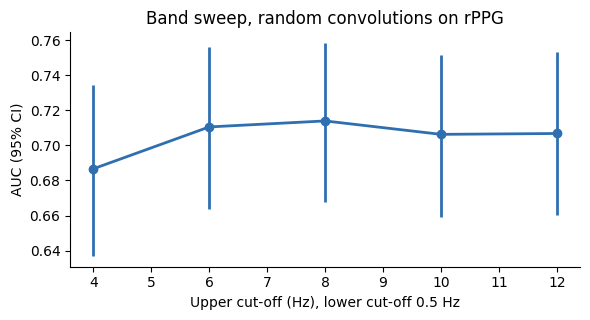

In [ ]:
_KERN = {}
def kernels(L, seed=0):
    if (L, seed) not in _KERN:
        rg = np.random.default_rng(seed); nfft = 2 * L; ks, dil = [], []
        for _ in range(N_KERNELS):
            k = rg.normal(size=rg.choice([7, 9, 11])); k -= k.mean(); d = int(2 ** rg.uniform(0, np.log2((L - 1) / (len(k) - 1)) * .55)); kk = np.zeros((len(k) - 1) * d + 1); kk[::d] = k
            ks.append(np.fft.rfft(kk, nfft)); dil.append(len(kk))
        _KERN[(L, seed)] = (ks, dil)
    return _KERN[(L, seed)]
def rand_features(sig, win_s=20, n_win=6):
    L = int(FS * win_s); nfft = 2 * L; ks, dil = kernels(L); windows, owner = [], []
    for i, x in enumerate(sig):
        if x is None or len(x) < L: continue
        x = np.nan_to_num(np.asarray(x, np.float32))
        for s in np.linspace(0, len(x) - L, n_win).astype(int):
            w = x[s:s + L]; windows.append((w - w.mean()) / (w.std() + 1e-6)); owner.append(i)
    F = np.fft.rfft(np.stack(windows), nfft, axis=1); out = np.zeros((len(windows), 2 * N_KERNELS), np.float32)
    for j, (K, l) in enumerate(zip(ks, dil)):
        c = np.fft.irfft(F * K, nfft, axis=1)[:, l - 1:L]; out[:, 2 * j] = (c > 0).mean(1); out[:, 2 * j + 1] = c.max(1)
    return pd.DataFrame(out).groupby(np.array(owner)).mean().reindex(range(len(sig))).values
RC = lambda: make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(C=.001, class_weight='balanced', max_iter=3000))
RC_REGION = 'Random conv: 4 regions separately, 0.5-8 Hz'
for hi in BAND_SWEEP:
    sig = band(POS_IDX, .5, float(hi)); cv(f'Random conv: regions averaged, 0.5-{hi} Hz', sk_session(RC, rand_features([None if a is None else a.mean(0) for a in sig])), 'Band sweep, rPPG'); del sig
RC_X = np.hstack([rand_features([None if a is None else a[j] for a in SIG['pos4']]) for j in range(4)])
cv(RC_REGION, sk_session(RC, RC_X), 'Waveform, rPPG')
cv('Random conv: contact PPG 0.5-8 Hz (ceiling)', sk_session(RC, rand_features(PPG_W)), 'Contact ceiling')
BS = pd.DataFrame([(hi, RES[f'Random conv: regions averaged, 0.5-{hi} Hz']['auc'], RES[f'Random conv: regions averaged, 0.5-{hi} Hz']['auc_lo'], RES[f'Random conv: regions averaged, 0.5-{hi} Hz']['auc_hi']) for hi in BAND_SWEEP], columns=['hi_hz', 'auc', 'lo', 'hi'])
if len(BS) > 1:
    fig, ax = plt.subplots(figsize=(6, 3.3)); ax.errorbar(BS.hi_hz, BS.auc, yerr=[BS.auc - BS.lo, BS.hi - BS.auc], fmt='-o', color=BLUE, lw=2, ms=6)
    ax.set(xlabel='Upper cut-off (Hz), lower cut-off 0.5 Hz', ylabel='AUC (95% CI)', title='Band sweep, random convolutions on rPPG'); ax.spines[['top', 'right']].set_visible(False); plt.tight_layout(); plt.savefig(f'{OUT}/band_sweep.png', dpi=150); plt.show()

## 7. CNNs
ResNet1D as in Week 8b, without the tabular branch (it lowered AUC there).

**Improved training** (used everywhere except the replication row):
- Augmentation: time stretch ±8%, Gaussian noise, and dropping one face region at random (all channels of that region).
- Cosine learning-rate schedule, light label smoothing.
- 2 seeds per fold (`CNN_SEEDS`), averaged. Each seed also uses a different 10% of training people for early stopping.
- Test predictions average windows every 5 s instead of 10 s.

| Row | Input | Why |
|---|---|---|
| Replication | 4 POS regions, Week 8b training | Is 0.737 reproducible? |
| Improved training | 4 POS regions | Effect of training alone |
| **Primary** | 4 regions × 3 algorithms | Effect of the extra algorithms |
| Ablations | forehead only, cheeks only, whole-face box only | A forehead-only model cannot see the beard area |
| Ceiling | contact PPG 0.5–8 Hz | |
| Controls | shuffled sex; high vs low contact HR | |

In [ ]:
import torch, torch.nn as nn
DEV = torch.device('cuda' if torch.cuda.is_available() else 'cpu'); WIN = int(WIN_S * FS); print('device:', DEV)
if str(DEV) == 'cpu' and RUN_CNN: print('WARNING: no GPU. The CNN section will take many hours. Set RUN_CNN = False or change the runtime.')
def conv_blk(i, o, k=7): return nn.Sequential(nn.Conv1d(i, o, k, padding=k // 2), nn.BatchNorm1d(o), nn.ReLU(), nn.MaxPool1d(2))
class ResBlock(nn.Module):
    def __init__(self, i, o, stride=2, k=15):
        super().__init__()
        self.net = nn.Sequential(nn.Conv1d(i, o, k, stride=stride, padding=k // 2), nn.BatchNorm1d(o), nn.ReLU(), nn.Dropout(.1), nn.Conv1d(o, o, k, padding=k // 2), nn.BatchNorm1d(o))
        self.skip = nn.Sequential(nn.Conv1d(i, o, 1, stride=stride), nn.BatchNorm1d(o)); self.act = nn.ReLU()
    def forward(self, x): return self.act(self.net(x) + self.skip(x))
class Net(nn.Module):
    def __init__(self, in_ch):
        super().__init__()
        self.enc = nn.Sequential(nn.Conv1d(in_ch, 32, 15, stride=2, padding=7), nn.BatchNorm1d(32), nn.ReLU(), ResBlock(32, 32), ResBlock(32, 64), ResBlock(64, 64))
        self.head = nn.Sequential(nn.Dropout(.4), nn.Linear(64, 1))
    def forward(self, x): return self.head(self.enc(x).mean(-1)).squeeze(-1)

def zwin(x): return (x - x.mean(-1, keepdims=True)) / (x.std(-1, keepdims=True) + 1e-6)
def sample(items, sig, flag, rng, aug=False, ch_group=1):
    C = sig[items[0]].shape[0]; X = np.empty((len(items), C + 1, WIN), np.float32); n_groups = C // ch_group
    for n, i in enumerate(items):
        T = sig[i].shape[1]; L = min(T, int(round(WIN * rng.uniform(.92, 1.08)))) if aug else WIN; st = rng.integers(0, T - L + 1); seg = sig[i][:, st:st + L].astype(np.float32)
        if L != WIN:
            x = np.linspace(0, L - 1, WIN); i0 = np.floor(x).astype(int); w = (x - i0).astype(np.float32); i1 = np.minimum(i0 + 1, L - 1); seg = seg[:, i0] * (1 - w) + seg[:, i1] * w
        seg = zwin(seg)
        if aug:
            seg = seg + rng.normal(0, rng.uniform(0, .3), seg.shape).astype(np.float32)
            if n_groups > 1 and rng.random() < .3: g = rng.integers(n_groups); seg[g * ch_group:(g + 1) * ch_group] = 0
        X[n, :C] = seg; X[n, C] = flag[i]
    return X
@torch.no_grad()
def predict(model, sig, flag, idx, stride_s=10):
    model.eval(); out = np.full(len(idx), np.nan); stride = int(stride_s * FS)
    for n, i in enumerate(idx):
        if sig[i] is None or sig[i].shape[1] < WIN: continue
        st = np.arange(0, sig[i].shape[1] - WIN + 1, stride); C = sig[i].shape[0]; X = np.empty((len(st), C + 1, WIN), np.float32)
        for m, s in enumerate(st): X[m, :C] = zwin(sig[i][:, s:s + WIN]); X[m, C] = flag[i]
        out[n] = float(model(torch.from_numpy(X).to(DEV)).mean().cpu())
    return out
def fit_predict(sig, flag, y, ids, tr, te, seed, improved=True, ch_group=1):
    # sig: list of (channels, samples) arrays or None. Returns P(male) for sessions te.
    rng = np.random.default_rng(seed); torch.manual_seed(seed); people = pd.Series(y[tr], index=ids[tr]).groupby(level=0).first()
    val_ids = set(np.concatenate([rng.choice(people.index[people == c], max(3, int(.1 * (people == c).sum())), replace=False) for c in (0, 1)]))
    usable = [i for i in tr if sig[i] is not None and sig[i].shape[1] >= WIN]; fit = np.array([i for i in usable if ids[i] not in val_ids]); val = np.array([i for i in usable if ids[i] in val_ids])
    model = Net(sig[fit[0]].shape[0] + 1).to(DEV); pos = float(y[fit].mean()); pw = torch.tensor((1 - pos) / pos, dtype=torch.float32, device=DEV)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-3)
    n_steps = EPOCHS * int(np.ceil(len(fit) * WIN_PER_SESSION / BATCH)); sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, max(n_steps, 1)) if improved else None
    smooth, stride = (.05, 5) if improved else (0., 10); best, state, bad = -1., None, 0
    for ep in range(EPOCHS):
        model.train(); order = rng.permutation(np.repeat(fit, WIN_PER_SESSION))
        for b in range(0, len(order), BATCH):
            ch = order[b:b + BATCH]
            if len(ch) < 2: continue
            X = torch.from_numpy(sample(ch, sig, flag, rng, improved, ch_group)).to(DEV); t = torch.from_numpy((y[ch] * (1 - 2 * smooth) + smooth).astype(np.float32)).to(DEV)
            loss = nn.functional.binary_cross_entropy_with_logits(model(X), t, pos_weight=pw); opt.zero_grad(); loss.backward(); opt.step()
            if sched is not None: sched.step()
        pv = predict(model, sig, flag, val, stride); f = pd.DataFrame(dict(i=ids[val], y=y[val], p=pv)).dropna().groupby('i').mean(); auc = roc_auc_score(f.y.astype(int), f.p)
        if auc > best + 1e-4: best, bad, state = auc, 0, {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE: break
    model.load_state_dict(state); return 1 / (1 + np.exp(-predict(model, sig, flag, te, stride)))

# Self-test on planted data: pulses at two frequencies must be separable. Stops the notebook if the CNN code is broken.
_r = np.random.default_rng(0); _y = np.repeat([0, 1], 80); _ids = np.arange(160); _t = np.arange(900) / FS
_s = [np.stack([np.sin(2 * np.pi * (1. + .5 * c) * _t + _r.uniform(0, 6)) + _r.normal(0, .3, 900) for _ in range(3)]).astype(np.float32) for c in _y]
_ep = EPOCHS; EPOCHS = 10; _o = _r.permutation(160)
for _imp in (False, True):
    _p = fit_predict(_s, np.zeros(160, np.float32), _y, _ids, _o[:120], _o[120:], 0, _imp, 3); _au = roc_auc_score(_y[_o[120:]], _p)
    print(f'self-test, improved={_imp}: AUC {_au:.2f}'); assert _au > .75, 'CNN self-test failed'
EPOCHS = _ep

device: cuda
self-test, improved=False: AUC 1.00
self-test, improved=True: AUC 1.00


In [ ]:
def cnn_fn(key, improved=True, seeds=None, chans=None):
    seeds = CNN_SEEDS if seeds is None else seeds
    def fn(tr, te, y, r, k):
        sig = SIG[key] if chans is None else [None if a is None else a[chans] for a in SIG['multi12']]
        ys = y[SESS_POS]; a, b = np.where(np.isin(SESS_POS, tr))[0], np.where(np.isin(SESS_POS, te))[0]; lg = []
        for s in range(seeds):
            p = np.clip(fit_predict(sig, FLAG, ys, SESS_IDS, a, b, 1000 * r + 10 * k + s, improved, CH_GROUP[key]), 1e-6, 1 - 1e-6); lg.append(np.log(p / (1 - p)))
        return to_person(1 / (1 + np.exp(-np.nanmean(lg, 0))), b, te)
    return fn
PRIMARY = 'CNN primary: 4 regions x POS/CHROM/green'
if RUN_CNN:
    hr = D.groupby('patient_id').ppg_hr.mean().reindex(PEOPLE); HR_LAB = (hr > hr.median()).astype(int).values
    cv('Control: CNN predicts high contact HR', cnn_fn('pos4', False, 1), 'Control', labels=HR_LAB, repeats=1, cache=True)
    cv('Shuffled sex: CNN', cnn_fn('multi12', True, 1), 'Control', labels=PERM, repeats=1, cache=True)
    cv('CNN replication: 4 POS regions, Week 8b training', cnn_fn('pos4_week8b', False, 1), 'CNN, rPPG', repeats=CNN_REPEATS, cache=True)
    cv('CNN: 4 POS regions, improved training', cnn_fn('pos4', True), 'CNN, rPPG', repeats=CNN_REPEATS, cache=True)
    cv(PRIMARY, cnn_fn('multi12', True), 'CNN, rPPG', repeats=CNN_REPEATS, cache=True)
    if RUN_ABLATIONS:
        for nm in ('forehead3', 'cheeks6', 'face3'):
            label = {'forehead3': 'forehead only', 'cheeks6': 'both cheeks only', 'face3': 'whole-face box only'}[nm]
            cv(f'CNN ablation: {label}', cnn_fn(nm, True, 1, SIG[nm + '_idx']), 'CNN ablation', repeats=1, cache=True)
    cv('CNN: contact PPG 0.5-8 Hz (ceiling)', cnn_fn('ppg_wide', True, 1), 'Contact ceiling', repeats=1, cache=True)
else:
    print('RUN_CNN = False: CNN rows skipped.')

Control: CNN predicts high contact HR                      AUC 0.981 [0.972, 0.989]  bal.acc 0.927  acc(bal) 0.926  acc(acc rule) 0.931 [0.910, 0.952]  recall M 0.94 F 0.91
Shuffled sex: CNN                                          AUC 0.480 [0.434, 0.531]  bal.acc 0.475  acc(bal) 0.450  acc(acc rule) 0.600 [0.567, 0.640]  recall M 0.55 F 0.40
CNN replication: 4 POS regions, Week 8b training           AUC 0.664 [0.591, 0.735]  bal.acc 0.582  acc(bal) 0.506  acc(acc rule) 0.625 [0.567, 0.679]  recall M 0.81 F 0.35
CNN: 4 POS regions, improved training                      AUC 0.677 [0.633, 0.728]  bal.acc 0.633  acc(bal) 0.606  acc(acc rule) 0.692 [0.635, 0.747]  recall M 0.71 F 0.55
CNN primary: 4 regions x POS/CHROM/green                   AUC 0.816 [0.770, 0.861]  bal.acc 0.739  acc(bal) 0.768  acc(acc rule) 0.754 [0.717, 0.791]  recall M 0.65 F 0.83
CNN ablation: forehead only                                AUC 0.670 [0.625, 0.708]  bal.acc 0.612  acc(bal) 0.517  acc(acc rule) 0.642

## 8. Late fusion
Equal-weight average of logits. Nothing is fitted, so no test information can enter the weights.

**Fixed in advance:** "Fusion, rPPG only" = primary CNN + random conv on 4 regions + person HGB on all rPPG tabular. If the CNN was not run, the two-part version is used and labelled as such.

In [ ]:
def fuse(name, parts, group):
    parts = [p for p in parts if p in PRED]
    if len(parts) < 2: print(f'{name}: skipped, needs 2+ parts'); return
    reps = sorted(set.intersection(*[set(PRED[p].repeat.unique()) for p in parts])); out = []
    for r in reps:
        fr = [PRED[p][PRED[p].repeat == r] for p in parts]; base = fr[0].copy(); pi = base.const.values
        lg = np.mean([np.log(np.clip(f.reindex(base.index).p.values, 1e-6, 1 - 1e-6) / (1 - np.clip(f.reindex(base.index).p.values, 1e-6, 1 - 1e-6))) for f in fr], axis=0)
        base['p'] = 1 / (1 + np.exp(-lg)); base['cal'] = base.p * pi / (base.p * pi + (1 - base.p) * (1 - pi)); out.append(base)
    record(name, pd.concat(out), group)
FINAL = 'Fusion, rPPG only (primary)' if PRIMARY in PRED else 'Fusion, rPPG only, without CNN (primary)'
CORE = [PRIMARY, RC_REGION, PERSON_R]
fuse(FINAL, CORE, 'Fusion, rPPG')
if PRIMARY in PRED: fuse('Fusion, rPPG only, without CNN', [RC_REGION, PERSON_R], 'Fusion, rPPG')
fuse('Fusion, rPPG + appearance', CORE + ['Appearance: per-region skin colour (logistic)'], 'With non-rPPG')
fuse('Fusion, rPPG + age and BMI', CORE + ['Age + BMI (logistic)'], 'With non-rPPG')
fuse('Fusion, rPPG + appearance + age and BMI', CORE + ['Appearance: per-region skin colour (logistic)', 'Age + BMI (logistic)'], 'With non-rPPG')

Fusion, rPPG only (primary)                                AUC 0.824 [0.784, 0.858]  bal.acc 0.736  acc(bal) 0.781  acc(acc rule) 0.745 [0.709, 0.778]  recall M 0.60 F 0.87
Fusion, rPPG only, without CNN                             AUC 0.756 [0.704, 0.803]  bal.acc 0.690  acc(bal) 0.740  acc(acc rule) 0.725 [0.687, 0.763]  recall M 0.54 F 0.84
Fusion, rPPG + appearance                                  AUC 0.844 [0.808, 0.878]  bal.acc 0.763  acc(bal) 0.801  acc(acc rule) 0.747 [0.711, 0.783]  recall M 0.65 F 0.88
Fusion, rPPG + age and BMI                                 AUC 0.831 [0.793, 0.865]  bal.acc 0.747  acc(bal) 0.788  acc(acc rule) 0.740 [0.701, 0.778]  recall M 0.62 F 0.87
Fusion, rPPG + appearance + age and BMI                    AUC 0.846 [0.812, 0.880]  bal.acc 0.763  acc(bal) 0.798  acc(acc rule) 0.742 [0.702, 0.779]  recall M 0.66 F 0.87


## 9. Checks
1. **Recording day.** The fusion parts are rerun with folds grouped by recording day, so test days are never seen in training.
2. **Paired AUC differences** on the same bootstrap people: is the fusion really above age + BMI, the Week 8 reference, and is the primary CNN above the replication?
3. **Age/BMI-stratified AUC** and **added value over age + BMI**, as in Week 8b.

In [ ]:
DAY_P = None
if RUN_DAY_CHECK:
    fr = db_all[(db_all.camera == 'FullHDwebcam') & (db_all.step == 'before')].drop_duplicates('patient_id').set_index('patient_id').reindex(PEOPLE)
    def first_day(m):
        try:
            with open(Path(ROOT)/'raw'/str(m), errors='ignore') as fh:
                for ln in fh:
                    g = TS_RE.search(ln)
                    if g: return pd.Timestamp(g.group(1).replace(',', '.')).normalize()
        except Exception: pass
        return pd.NaT
    with ThreadPoolExecutor(12) as ex: days = pd.Series(list(ex.map(first_day, fr.meta.values)), index=PEOPLE)
    if days.notna().mean() > .9:
        DAY_P = days.astype(str).values; print(f'{days.nunique()} recording days found')
        cv(f'{PERSON_R}, folds by recording day', sk_person(HGB, T_RALL), 'Day check', groups=DAY_P)
        cv(f'{RC_REGION}, folds by recording day', sk_session(RC, RC_X), 'Day check', groups=DAY_P)
        if RUN_CNN: cv(f'{PRIMARY}, folds by recording day', cnn_fn('multi12', True, 1), 'Day check', repeats=1, groups=DAY_P, cache=True)
        fuse(f'{FINAL}, folds by recording day', [f'{PRIMARY}, folds by recording day', f'{RC_REGION}, folds by recording day', f'{PERSON_R}, folds by recording day'], 'Day check')
    else: print('Recording dates unavailable: check skipped.')

def delta_auc(a, b):
    reps = sorted(set(PRED[a].repeat) & set(PRED[b].repeat)); pts, vals = [], []
    for r in reps:
        x = PRED[a][PRED[a].repeat == r]; z = PRED[b][PRED[b].repeat == r].reindex(x.index); y, pa, pb = x.y.values.astype(int), x.p.values, z.p.values; rg = np.random.default_rng(1000 + int(r))
        pts.append(roc_auc_score(y, pa) - roc_auc_score(y, pb))
        for _ in range(N_BOOT):
            ix = rg.integers(0, len(y), len(y))
            if 0 < y[ix].sum() < len(ix): vals.append(roc_auc_score(y[ix], pa[ix]) - roc_auc_score(y[ix], pb[ix]))
    return dict(gain=np.mean(pts), lo=np.percentile(vals, 2.5), hi=np.percentile(vals, 97.5))
pairs = [(FINAL, 'Age + BMI (logistic)'), (FINAL, 'Session HGB: rPPG features (Week 8 reference)'), (PERSON_R, 'Session HGB: rPPG features (Week 8 reference)'),
         (PRIMARY, 'CNN replication: 4 POS regions, Week 8b training'), ('CNN: 4 POS regions, improved training', 'CNN replication: 4 POS regions, Week 8b training'), (PRIMARY, 'CNN: 4 POS regions, improved training'),
         ('Fusion, rPPG + age and BMI', 'Age + BMI (logistic)')]
GAINS = pd.DataFrame({f'{a}  minus  {b}': delta_auc(a, b) for a, b in pairs if a in PRED and b in PRED}).T.round(3); GAINS.to_csv(f'{OUT}/paired_auc_differences.csv'); display(GAINS)

ref = PRED['Age + BMI (logistic)'].groupby('id').p.mean(); strata = pd.qcut(ref, 5, labels=False, duplicates='drop')
def strat_auc(name):
    f = PRED[name].groupby('id')[['y', 'p']].mean(); y, p, s = f.y.values.astype(int), f.p.values, strata.reindex(f.index).values
    def calc(ix):
        tot, w = 0., 0
        for g in np.unique(s):
            m = ix[s[ix] == g]; yy = y[m]
            if yy.sum() >= 3 and (1 - yy).sum() >= 3: tot += roc_auc_score(yy, p[m]) * len(m); w += len(m)
        return tot / w
    rg = np.random.default_rng(3); return calc(np.arange(len(y))), *np.percentile([calc(rg.integers(0, len(y), len(y))) for _ in range(500)], [2.5, 97.5])
def added_value(name):
    f = PRED[name].groupby('id')[['y', 'p']].mean(); y = f.y.values.astype(int); A = SimpleImputer(strategy='median').fit_transform(P.reindex(f.index)[['age', 'bmi']])
    lg = np.log(np.clip(f.p.values, 1e-6, 1 - 1e-6) / (1 - np.clip(f.p.values, 1e-6, 1 - 1e-6))); B = np.column_stack([A, lg]); pa, pb = np.zeros(len(y)), np.zeros(len(y))
    for tr, te in StratifiedKFold(5, shuffle=True, random_state=0).split(A, y):
        for X, o in ((A, pa), (B, pb)): o[te] = make_pipeline(StandardScaler(), LogisticRegression(C=1., class_weight='balanced', max_iter=2000)).fit(X[tr], y[tr]).predict_proba(X[te])[:, 1]
    rg = np.random.default_rng(5); ds = []
    for _ in range(1000):
        ix = rg.integers(0, len(y), len(y))
        if 0 < y[ix].sum() < len(ix): ds.append(roc_auc_score(y[ix], pb[ix]) - roc_auc_score(y[ix], pa[ix]))
    return roc_auc_score(y, pb) - roc_auc_score(y, pa), *np.percentile(ds, [2.5, 97.5])
rows = []
for n in [k for k in RES if GROUP[k] in ('Person, rPPG', 'Waveform, rPPG', 'CNN, rPPG', 'CNN ablation', 'Fusion, rPPG')]:
    a, v = strat_auc(n), added_value(n); rows.append(dict(model=n, strat_auc=a[0], strat_lo=a[1], strat_hi=a[2], gain_over_age_bmi=v[0], gain_lo=v[1], gain_hi=v[2]))
CHECK = pd.DataFrame(rows).set_index('model').round(3); CHECK.to_csv(f'{OUT}/confound_checks.csv'); pd.set_option('display.width', 250, 'display.max_columns', 40); display(CHECK)

35 recording days found
Person HGB: all rPPG tabular, folds by recording day       AUC 0.677 [0.621, 0.731]  bal.acc 0.637  acc(bal) 0.684  acc(acc rule) 0.703 [0.661, 0.746]  recall M 0.50 F 0.78
Random conv: 4 regions separately, 0.5-8 Hz, folds by recording day AUC 0.776 [0.734, 0.813]  bal.acc 0.694  acc(bal) 0.733  acc(acc rule) 0.712 [0.676, 0.747]  recall M 0.58 F 0.81
CNN primary: 4 regions x POS/CHROM/green, folds by recording day AUC 0.796 [0.759, 0.828]  bal.acc 0.706  acc(bal) 0.731  acc(acc rule) 0.744 [0.711, 0.782]  recall M 0.63 F 0.78
Fusion, rPPG only (primary), folds by recording day        AUC 0.800 [0.762, 0.835]  bal.acc 0.715  acc(bal) 0.759  acc(acc rule) 0.739 [0.706, 0.774]  recall M 0.58 F 0.85


,gain,lo,hi
"Fusion, rPPG only (primary) minus Age + BMI (logistic)",0.130,0.081,0.179
"Fusion, rPPG only (primary) minus Session HGB: rPPG features (Week 8 reference)",0.147,0.103,0.188
Person HGB: all rPPG tabular minus Session HGB: rPPG features (Week 8 reference),0.004,-0.041,0.049
"CNN primary: 4 regions x POS/CHROM/green minus CNN replication: 4 POS regions, Week 8b training",0.152,0.048,0.256
"CNN: 4 POS regions, improved training minus CNN replication: 4 POS regions, Week 8b training",0.013,-0.050,0.102
"CNN primary: 4 regions x POS/CHROM/green minus CNN: 4 POS regions, improved training",0.139,0.073,0.194
"Fusion, rPPG + age and BMI minus Age + BMI (logistic)",0.136,0.095,0.178


,strat_auc,strat_lo,strat_hi,gain_over_age_bmi,gain_lo,gain_hi
model,,,,,,
"Person HGB: rPPG HRV + quality, before/after/change",0.614,0.559,0.668,0.034,0.002,0.065
Person HGB: rPPG pulse shape (new),0.663,0.608,0.716,0.048,0.013,0.087
Person HGB: rPPG template beat (new),0.582,0.511,0.645,0.009,-0.022,0.036
Person HGB: all rPPG tabular,0.648,0.592,0.700,0.049,0.014,0.084
Person extra trees: all rPPG tabular,0.659,0.606,0.713,0.051,0.014,0.087
Person RBF SVM: all rPPG tabular,0.662,0.611,0.712,0.055,0.017,0.093
Person logistic: all rPPG tabular,0.633,0.581,0.686,0.036,-0.001,0.068
"Random conv: 4 regions separately, 0.5-8 Hz",0.754,0.710,0.799,0.102,0.063,0.140
"CNN replication: 4 POS regions, Week 8b training",0.673,0.629,0.722,0.049,0.013,0.084


## 10. Results

,Group,Repeats,AUC,lo,hi,Bal acc,Acc (balanced rule),Recall M,Recall F,Acc (accuracy rule),lo,hi,Acc gain vs always-female,lo,hi,Recall M (acc rule),Recall F (acc rule),MCC,PR-AUC,Brier skill %
Session HGB: rPPG features (Week 8 reference),Reference,5.0,0.675,0.622,0.723,0.635,0.669,0.535,0.736,0.690,0.652,0.726,0.024,-0.003,0.052,0.180,0.946,0.267,0.523,8.510
"Person HGB: rPPG HRV + quality, before/after/change","Person, rPPG",5.0,0.653,0.593,0.707,0.619,0.661,0.493,0.746,0.690,0.649,0.729,0.024,-0.008,0.059,0.257,0.907,0.239,0.514,5.094
Person HGB: rPPG pulse shape (new),"Person, rPPG",5.0,0.680,0.623,0.728,0.638,0.684,0.502,0.775,0.715,0.676,0.751,0.049,0.018,0.082,0.306,0.920,0.281,0.569,9.883
Person HGB: rPPG template beat (new),"Person, rPPG",5.0,0.595,0.535,0.652,0.581,0.633,0.426,0.737,0.682,0.644,0.717,0.016,-0.016,0.050,0.246,0.901,0.165,0.474,-1.769
Person HGB: all rPPG tabular,"Person, rPPG",5.0,0.679,0.621,0.734,0.641,0.689,0.497,0.785,0.717,0.681,0.753,0.051,0.020,0.082,0.303,0.925,0.288,0.567,9.625
Person extra trees: all rPPG tabular,"Person, rPPG",5.0,0.701,0.647,0.752,0.659,0.724,0.462,0.855,0.701,0.665,0.737,0.036,0.016,0.057,0.141,0.983,0.345,0.582,10.259
Person RBF SVM: all rPPG tabular,"Person, rPPG",5.0,0.703,0.652,0.752,0.627,0.717,0.355,0.899,0.684,0.645,0.722,0.019,0.003,0.038,0.089,0.983,0.309,0.560,5.447
Person logistic: all rPPG tabular,"Person, rPPG",5.0,0.680,0.628,0.730,0.644,0.664,0.585,0.703,0.712,0.669,0.751,0.046,0.008,0.084,0.343,0.897,0.278,0.535,8.810
Appearance: per-region skin colour (logistic),Appearance,5.0,0.728,0.683,0.776,0.671,0.685,0.629,0.713,0.726,0.689,0.763,0.060,0.025,0.095,0.358,0.911,0.329,0.577,14.558
Appearance: per-region skin colour (HGB),Appearance,5.0,0.762,0.718,0.802,0.689,0.719,0.598,0.780,0.721,0.682,0.758,0.056,0.017,0.094,0.364,0.901,0.375,0.603,17.023


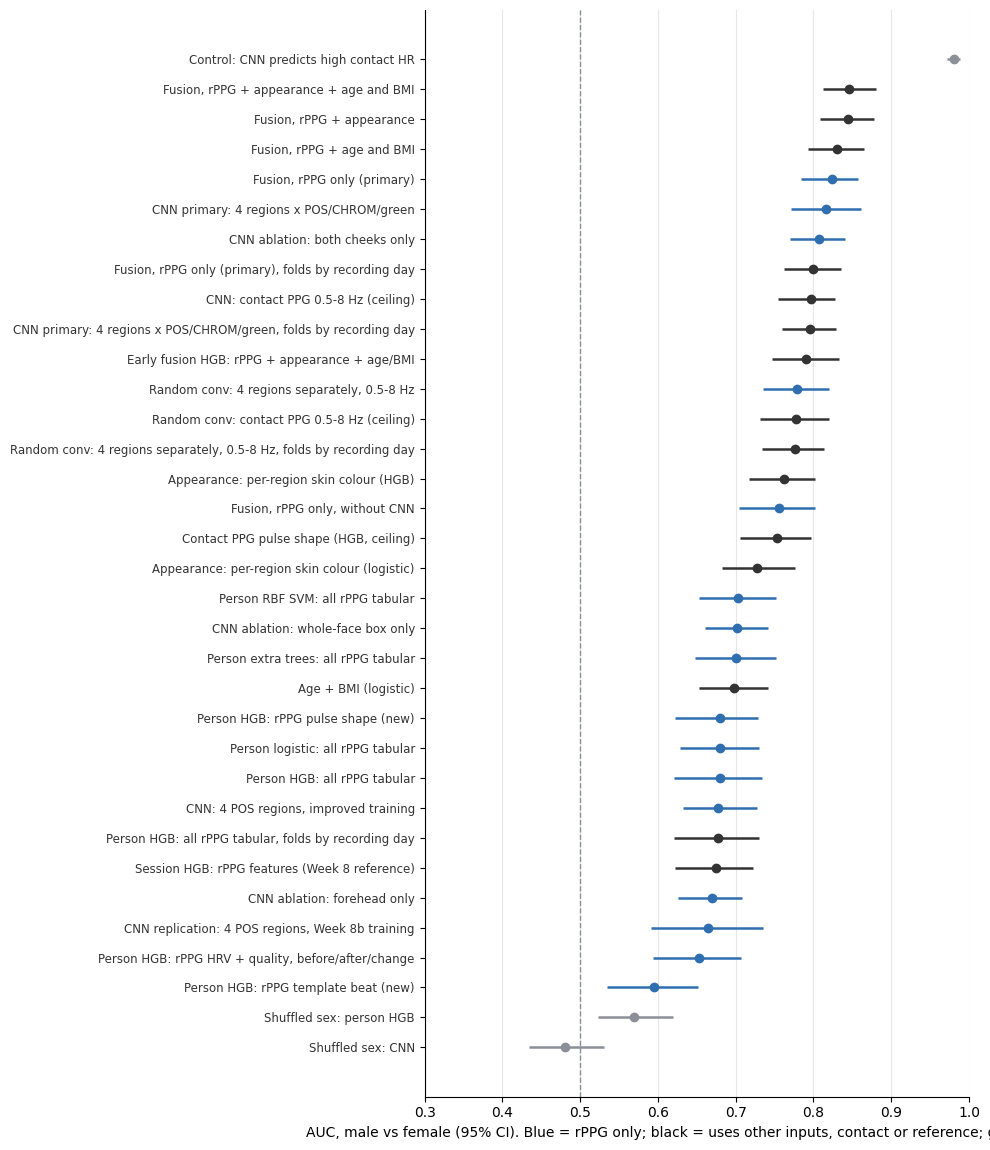

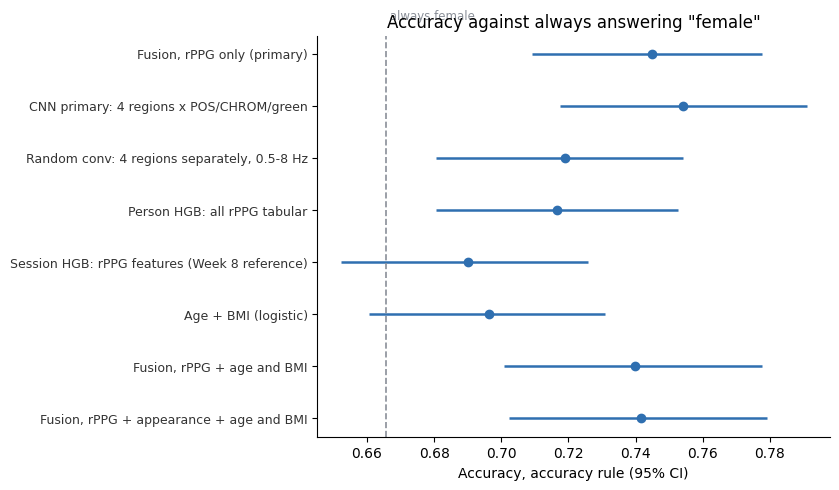

In [ ]:
T = pd.DataFrame(RES).T; T.insert(0, 'group', pd.Series(GROUP)); T.to_csv(f'{OUT}/sex_v3_metrics.csv')
cols = ['group', 'repeats', 'auc', 'auc_lo', 'auc_hi', 'bal_acc', 'acc', 'recall_m', 'recall_f', 'acc_cal', 'acc_cal_lo', 'acc_cal_hi', 'acc_gain', 'acc_gain_lo', 'acc_gain_hi', 'recall_m_cal', 'recall_f_cal', 'mcc', 'ap', 'brier_skill']
V = T[cols].copy(); V[cols[1:]] = V[cols[1:]].astype(float).round(3)
V.columns = ['Group', 'Repeats', 'AUC', 'lo', 'hi', 'Bal acc', 'Acc (balanced rule)', 'Recall M', 'Recall F', 'Acc (accuracy rule)', 'lo ', 'hi ', 'Acc gain vs always-female', 'lo  ', 'hi  ', 'Recall M (acc rule)', 'Recall F (acc rule)', 'MCC', 'PR-AUC', 'Brier skill %']
display(V)

S = T[~T.group.isin(['Band sweep, rPPG'])].astype({'auc': float, 'auc_lo': float, 'auc_hi': float}).sort_values('auc')
col = lambda g: GREY if g in ('Control',) else INK if g in ('Not rPPG', 'Appearance', 'With non-rPPG', 'Contact ceiling', 'Reference', 'Day check') else BLUE
fig, ax = plt.subplots(figsize=(10, max(4, .3 * len(S) + 1.4)))
for i, (n, r) in enumerate(S.iterrows()): ax.errorbar(r.auc, i, xerr=[[r.auc - r.auc_lo], [r.auc_hi - r.auc]], fmt='o', ms=6, lw=1.8, color=col(r.group))
ax.axvline(.5, color=GREY, ls='--', lw=1); ax.set_yticks(range(len(S)), S.index, color=INK, fontsize=8.5)
ax.set(xlabel='AUC, male vs female (95% CI). Blue = rPPG only; black = uses other inputs, contact or reference; grey = control', xlim=(.3, 1)); ax.spines[['top', 'right']].set_visible(False); ax.grid(axis='x', color='#E6E6E6', lw=.8); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig(f'{OUT}/sex_v3_forest.png', dpi=150); plt.show()

show = [n for n in [FINAL, PRIMARY, RC_REGION, PERSON_R, 'Session HGB: rPPG features (Week 8 reference)', 'Age + BMI (logistic)', 'Fusion, rPPG + age and BMI', 'Fusion, rPPG + appearance + age and BMI'] if n in RES][::-1]
A = T.loc[show].astype({'acc_cal': float, 'acc_cal_lo': float, 'acc_cal_hi': float})
fig, ax = plt.subplots(figsize=(8.5, .45 * len(A) + 1.4)); ax.errorbar(A.acc_cal, range(len(A)), xerr=[A.acc_cal - A.acc_cal_lo, A.acc_cal_hi - A.acc_cal], fmt='o', ms=6, color=BLUE, lw=1.8)
ax.axvline(MAJ, color=GREY, ls='--', lw=1.2); ax.text(MAJ, len(A) - .4, ' always female', color=GREY, fontsize=8.5, va='bottom'); ax.set_yticks(range(len(A)), A.index, fontsize=9, color=INK)
ax.set(xlabel='Accuracy, accuracy rule (95% CI)', title='Accuracy against always answering "female"'); ax.spines[['top', 'right']].set_visible(False); plt.tight_layout(); plt.savefig(f'{OUT}/sex_v3_accuracy.png', dpi=150); plt.show()

## 11. Automatic verdict

In [ ]:
f = RES[FINAL]; ag = RES['Age + BMI (logistic)']; wk = RES['Session HGB: rPPG features (Week 8 reference)']
print(f"{FINAL}: AUC {f['auc']:.3f} [{f['auc_lo']:.3f}, {f['auc_hi']:.3f}], balanced accuracy {f['bal_acc']:.3f}")
print(f"  accuracy, accuracy rule {f['acc_cal']:.3f} [{f['acc_cal_lo']:.3f}, {f['acc_cal_hi']:.3f}] vs always-female {f['majority']:.3f}; recall M {f['recall_m_cal']:.2f}, F {f['recall_f_cal']:.2f}")
print(f"  accuracy, balanced rule {f['acc']:.3f}; recall M {f['recall_m']:.2f}, F {f['recall_f']:.2f}")
print(f"References: Week 8 session HGB {wk['auc']:.3f}; age + BMI {ag['auc']:.3f}")
sh = [RES[n]['auc'] for n in RES if GROUP[n] == 'Control' and n.startswith('Shuffled')]; print(f"Shuffled controls: {', '.join(f'{x:.3f}' for x in sh)}")
if 'Control: CNN predicts high contact HR' in RES: print(f"CNN positive control (high contact HR): {RES['Control: CNN predicts high contact HR']['auc']:.3f}")
print(f"Template beat correlation rPPG vs contact: {TPL_AGREE['same']:.2f} (another person {TPL_AGREE['other']:.2f})")
dk = f'{FINAL}, folds by recording day'
if dk in RES: print(f"Folds grouped by recording day: fusion AUC {RES[dk]['auc']:.3f} (was {f['auc']:.3f})")
print()
print('Fusion AUC above chance:', 'YES' if f['auc_lo'] > .5 else 'NO')
print('Fusion accuracy above always-female (accuracy rule, CI excludes 0):', 'YES' if f['acc_gain_lo'] > 0 else 'NO')
for key in (f'{FINAL}  minus  Age + BMI (logistic)', f'{FINAL}  minus  Session HGB: rPPG features (Week 8 reference)'):
    if key in GAINS.index: g = GAINS.loc[key]; print(f"{key}: {g.gain:+.3f} [{g.lo:+.3f}, {g.hi:+.3f}] ->", 'clearly higher' if g.lo > 0 else 'clearly lower' if g.hi < 0 else 'not clearly different')
for n in ('Shuffled sex: person HGB', 'Shuffled sex: CNN'):
    if n in RES and abs(RES[n]['auc'] - .5) > .08: print(f'WARNING: {n} is far from 0.5. Do not trust these results.')
if 'Control: CNN predicts high contact HR' in RES and RES['Control: CNN predicts high contact HR']['auc'] < .75: print('WARNING: the CNN positive control is weak. Do not trust the CNN rows.')
abl = {n: RES[n]['auc'] for n in RES if GROUP[n] == 'CNN ablation'}
if abl: print('Region ablations (AUC): ' + ', '.join(f"{n.split(': ')[1]} {a:.3f}" for n, a in abl.items()) + '. Compare forehead only with the cheeks: the forehead has no beard area.')

Fusion, rPPG only (primary): AUC 0.824 [0.784, 0.858], balanced accuracy 0.736
  accuracy, accuracy rule 0.745 [0.709, 0.778] vs always-female 0.666; recall M 0.30, F 0.97
  accuracy, balanced rule 0.781; recall M 0.60, F 0.87
References: Week 8 session HGB 0.675; age + BMI 0.698
Shuffled controls: 0.569, 0.480
CNN positive control (high contact HR): 0.981
Template beat correlation rPPG vs contact: 0.28 (another person 0.26)
Folds grouped by recording day: fusion AUC 0.800 (was 0.824)

Fusion AUC above chance: YES
Fusion accuracy above always-female (accuracy rule, CI excludes 0): YES
Fusion, rPPG only (primary)  minus  Age + BMI (logistic): +0.130 [+0.081, +0.179] -> clearly higher
Fusion, rPPG only (primary)  minus  Session HGB: rPPG features (Week 8 reference): +0.147 [+0.103, +0.188] -> clearly higher
Region ablations (AUC): forehead only 0.670, both cheeks only 0.807, whole-face box only 0.702. Compare forehead only with the cheeks: the forehead has no beard area.
